# 📘 11.5 Implicit Time Marching and the Crank–Nicolson Method

In Notebook **11.1**, we solved the diffusion equation using **Forward in Time, Centred in Space (FTCS)**. Notebook **11.4** showed why its explicit time step becomes restricted as the spatial grid is refined: for standard one-dimensional diffusion, $r=D\Delta t/(\Delta x)^2\leq 1/2$.

**Can we take a larger time step without that same stability restriction?** Before introducing Crank–Nicolson, we will first see how a **simple implicit method (backward Euler)** works. This reveals why future-time temperatures are coupled and why solving a linear system becomes necessary. Crank–Nicolson then follows naturally by **averaging diffusion at the current and future time levels**.

We will examine **time–space stencil diagrams**, work through a small matrix example, and compare schemes at the **same physical time**. The final interactive experiment allows you to change spatial and temporal resolutions.

### 🎯 Learning Objectives

> By the end of this notebook, you should be able to:
>
> * **Distinguish explicit and implicit time marching**, using time–space stencil diagrams.
> * **Construct** the backward-Euler diffusion update and explain why it requires a linear solve.
> * **Derive** Crank–Nicolson by averaging diffusion terms at two time levels.
> * **Form and solve** a small tridiagonal system for the next time level.
> * **Implement** Crank–Nicolson for one-dimensional diffusion with fixed-temperature boundaries.
> * **Compare** FTCS, backward Euler and Crank–Nicolson in their stability, accuracy and computational requirements.
> * **Use interactive controls** to investigate the effect of space and time resolution.
> * **Recognise** that unconditional linear stability does not guarantee accuracy or non-oscillatory results.

## 📂 11.5.0 How to use this notebook

This notebook continues from **11.4 (finite difference stability)**, and connects back to the **implicit ODE methods in Week 9** and **linear systems in Notebook 11.3**.

1. **Recall FTCS**, and read the diagrams showing which time-level values each method uses.
2. **Build backward Euler** as the simplest implicit diffusion method.
3. **Develop Crank–Nicolson** by averaging the diffusion terms at the old and new time levels.
4. **Solve a three-interior-node system**, then run the commented Python example.
5. **Compare time-step errors** using a known analytical solution.
6. **Explore stability interactively** by changing the spatial grid and time steps.

Run Python cells **in order**. The interactive controls use `ipywidgets`, and the same plotting function can be called directly if widgets do not render.

> **Scope:** We use a one-dimensional linear heat/diffusion equation with constant $D$, uniformly spaced grid points, and **fixed zero-temperature (Dirichlet) boundaries**. This lets us focus on the method; other boundary conditions are covered in Notebook 11.2.

## 📂 11.5.1 Why move beyond FTCS?

Consider the same heat/diffusion equation as in Notebook 11.4:

$$\frac{\partial T}{\partial t}=D\frac{\partial^2T}{\partial x^2},\qquad D>0.$$

Here $T(x,t)$ is temperature, $D$ is thermal diffusivity ($\mathrm{m^2/s}$), $j$ labels spatial nodes and $n$ labels time levels. The **Fourier number** is

$$r=\frac{D\Delta t}{(\Delta x)^2}.$$

The **explicit FTCS** update is

$$T_j^{n+1}=T_j^n+r\left(T_{j-1}^n-2T_j^n+T_{j+1}^n\right).$$

Every value on the **right-hand side is already known** at time $t_n$, so each new interior temperature can be updated directly. However, FTCS requires **$r\leq1/2$** for the standard 1D diffusion problem; halving $\Delta x$ requires reducing the largest stable $\Delta t$ by a factor of four.

An **implicit** method involves temperatures at the **new** time level on both sides of its equation. This requires more work per step, but may allow much larger time steps without instability. The next section shows how.

## 📂 11.5.2 Explicit versus implicit — first learn backward Euler

The goal in **all three methods** is to move **forward in physical time**, from $t_n$ to $t_{n+1}$. What changes is **the time level at which we evaluate spatial diffusion**.

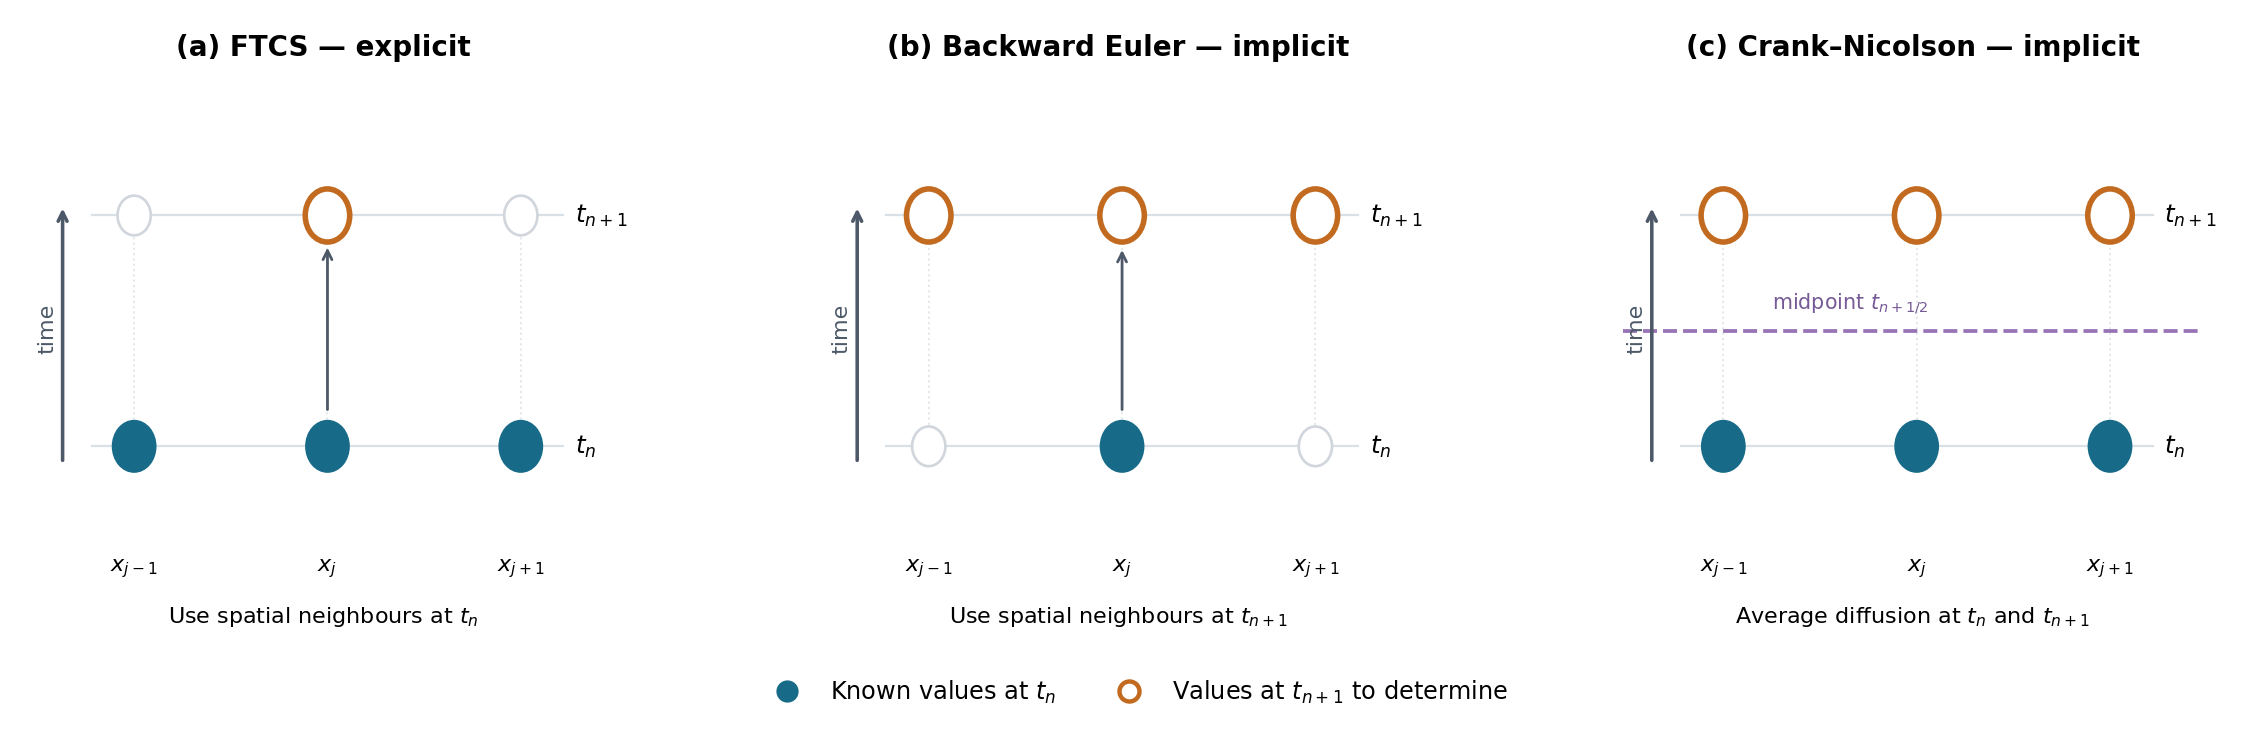

*Figure: An original schematic of the time–space stencils. Blue filled circles represent known temperatures at $t_n$; orange outlined circles represent next-time values that are not yet known. Grey points are shown for context. The spatial stencil consists of the indicated three neighbouring nodes.*

### Step 1 — Use the current time level: explicit FTCS

The familiar update evaluates the centred second spatial derivative **at $t_n$**:

$$\frac{T_j^{n+1}-T_j^n}{\Delta t}
=D\frac{T_{j-1}^{n}-2T_j^{n}+T_{j+1}^{n}}{(\Delta x)^2}.$$

This can be rearranged to calculate $T_j^{n+1}$ **directly** from known values.

### Step 2 — Use the next time level: backward Euler

Now use the *same spatial second-difference stencil*, but evaluate it **at $t_{n+1}$**:

$$\frac{T_j^{n+1}-T_j^n}{\Delta t}
=D\frac{T_{j-1}^{n+1}-2T_j^{n+1}+T_{j+1}^{n+1}}{(\Delta x)^2}.$$

Multiply by $\Delta t$, substitute $r=D\Delta t/(\Delta x)^2$, and collect **all unknown new temperatures on the left**:

$$\boxed{-rT_{j-1}^{n+1}+(1+2r)T_j^{n+1}-rT_{j+1}^{n+1}=T_j^n.}$$

**Why is this implicit?** To calculate the new value at node $j$, the equation also needs the **unknown new values at nodes $j-1$ and $j+1$**. The interior-node equations must therefore be solved **together**, not node by node as in FTCS.

For example, with three interior nodes and fixed-zero endpoints, backward Euler has the form

$$\underbrace{\begin{bmatrix}1+2r&-r&0\\-r&1+2r&-r\\0&-r&1+2r\end{bmatrix}}_{A_{\mathrm{BE}}}
\underbrace{\begin{bmatrix}T_1^{n+1}\\T_2^{n+1}\\T_3^{n+1}\end{bmatrix}}_{\text{unknown new temperatures}}
=\underbrace{\begin{bmatrix}T_1^n\\T_2^n\\T_3^n\end{bmatrix}}_{\text{known old temperatures}}.$$

This is the same kind of matrix equation, $A\mathbf T=\mathbf b$, introduced for elliptic PDEs in Notebook 11.3, except that **we solve a new system at every time step**.

> **Terminology:** *Backward* Euler refers to taking the time difference with respect to the **new endpoint** $t_{n+1}$. It **does not** mean marching backwards in physical time. For standard linear diffusion, backward Euler is unconditionally linearly stable and first-order accurate in time; the linear solve does not make the result automatically accurate.


## 📂 11.5.3 From backward Euler to Crank–Nicolson: average both time levels

Backward Euler evaluates diffusion only at the **future** time level. Crank–Nicolson takes the next step: **average the spatial diffusion at the old and new time levels**. This estimates diffusion over the time interval more accurately for smooth solutions.

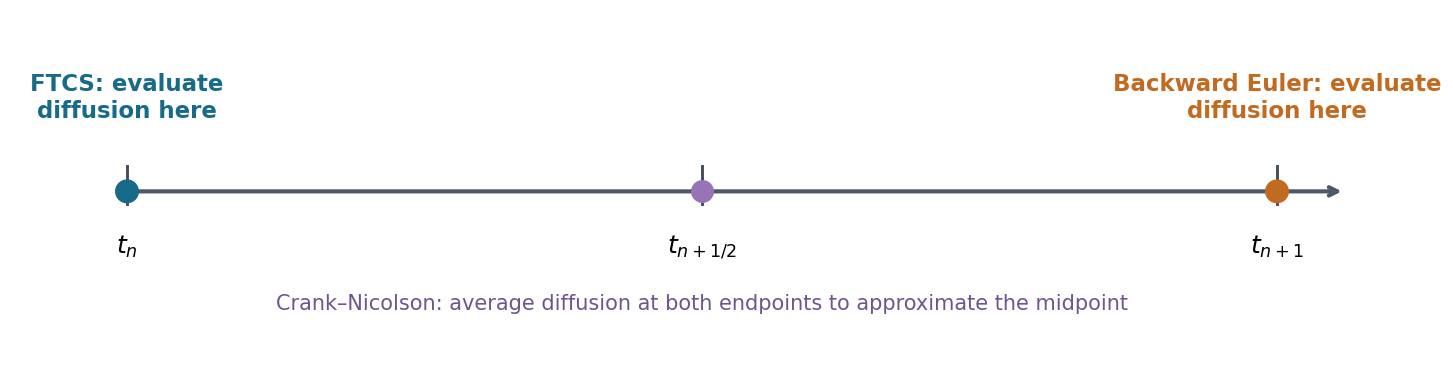

### Step 1 — Approximate the change in temperature over one time step

$$\frac{\partial T}{\partial t}\;\approx\;\frac{T_j^{n+1}-T_j^n}{\Delta t}.$$

### Step 2 — Apply the centred spatial difference at *both* time levels

Write $\delta_{xx}T_j^n=(T_{j-1}^n-2T_j^n+T_{j+1}^n)/(\Delta x)^2$. Crank–Nicolson uses

$$\frac{T_j^{n+1}-T_j^n}{\Delta t}
=\frac D2\left[\delta_{xx}T_j^{n}+\delta_{xx}T_j^{n+1}\right].$$

Writing both spatial differences in full shows **known** and **unknown** terms:

$$\frac{T_j^{n+1}-T_j^n}{\Delta t}
=\frac{D}{2(\Delta x)^2}
\left[\underbrace{T_{j-1}^{n}-2T_j^{n}+T_{j+1}^{n}}_{\text{known at }n}
+\underbrace{T_{j-1}^{n+1}-2T_j^{n+1}+T_{j+1}^{n+1}}_{\text{unknown at }n+1}\right].$$

### Step 3 — Rearrange into a system for the next temperatures

Multiply by $\Delta t$, substitute $r=D\Delta t/(\Delta x)^2$, and collect the new temperatures:

$$\boxed{-\frac r2 T_{j-1}^{n+1}+(1+r)T_j^{n+1}-\frac r2 T_{j+1}^{n+1}
=\frac r2 T_{j-1}^{n}+(1-r)T_j^{n}+\frac r2 T_{j+1}^{n}.}$$

Both **backward Euler and Crank–Nicolson are implicit**, but Crank–Nicolson averages information from **two** time levels rather than using only the future one.

For sufficiently smooth solutions on a uniform grid:

| Method | Time accuracy | Space accuracy (centred stencil) |
|---|---|---|
| FTCS | First order | Second order |
| Backward Euler | First order | Second order |
| **Crank–Nicolson** | **Second order** | Second order |

The higher order is useful, but remember: **accuracy order and stability are different properties**.

## 📂 11.5.4 Assemble the tridiagonal matrix system

Like backward Euler, Crank–Nicolson requires a coupled solve. Now we build its particular matrices.

Use **three interior nodes**, $j=1,2,3$, with fixed boundary temperatures $T_0=T_4=0$. Put the unknown new temperatures into a vector:

$$\mathbf T^{n+1}=\begin{bmatrix}T_1^{n+1}\\T_2^{n+1}\\T_3^{n+1}\end{bmatrix}.$$

Writing the update from §11.5.3 at each interior node gives

$$\underbrace{\begin{bmatrix}
1+r&-r/2&0\\
-r/2&1+r&-r/2\\
0&-r/2&1+r
\end{bmatrix}}_{A}
\mathbf T^{n+1}
=\underbrace{\begin{bmatrix}
1-r&r/2&0\\
r/2&1-r&r/2\\
0&r/2&1-r
\end{bmatrix}}_{B}\mathbf T^n.$$

The matrices are **tridiagonal**: only the main diagonal and the two neighbouring diagonals contain nonzero entries. This is a useful special structure of the one-dimensional diffusion problem.

For a concrete first step, take $r=0.4$ and $\mathbf T^0=[0,1,0]^T$. Then

$$A=\begin{bmatrix}1.4&-0.2&0\\-0.2&1.4&-0.2\\0&-0.2&1.4\end{bmatrix},\qquad
B\mathbf T^0=\begin{bmatrix}0.2\\0.6\\0.2\end{bmatrix}.$$

The next task is **solve $A\mathbf T^1=B\mathbf T^0$**; we do not calculate $\mathbf T^1$ by simply dividing each right-hand-side entry by the diagonal of $A$.

**Boundary-condition note:** For nonzero prescribed endpoint temperatures, the first and last right-hand-side entries also receive $\tfrac r2(T_{\mathrm{end}}^{n}+T_{\mathrm{end}}^{n+1})$. Our code uses zero endpoints, so these contributions are zero. See Notebook 11.2 for other boundary conditions.

Matrix A (unknown next-time temperatures):
 [[ 1.4 -0.2  0. ]
 [-0.2  1.4 -0.2]
 [ 0.  -0.2  1.4]]

Matrix B (known current-time temperatures):
 [[0.6 0.2 0. ]
 [0.2 0.6 0.2]
 [0.  0.2 0.6]]

Right-hand side B @ T_current: [0.2 0.6 0.2]
Next-step interior temperatures: [0.212766 0.489362 0.212766]
Linear-system residual: 5.55e-17

Backward-Euler matrix A_be:
 [[ 1.8 -0.4  0. ]
 [-0.4  1.8 -0.4]
 [ 0.  -0.4  1.8]]
Backward-Euler next temperatures: [0.136986 0.616438 0.136986]
Backward-Euler residual: 2.22e-16


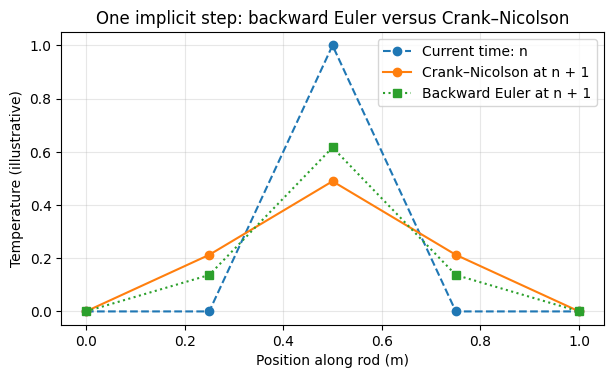

In [ ]:
# @title 💻 Example 1: Compare one backward-Euler and Crank–Nicolson time step

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. SET UP THE SMALL THREE-INTERIOR-NODE EXAMPLE
# ============================================================

r = 0.40                         # Fourier number: D*dt/dx**2
interior_initial = np.array([0.0, 1.0, 0.0])
m = len(interior_initial)       # Three interior unknown temperatures

# ============================================================
# 2. BUILD MATRICES A (NEW VALUES) AND B (OLD VALUES)
# ============================================================

# np.diag(..., k=0) puts values on the MAIN diagonal.
# k=+1 and k=-1 put values on the adjacent diagonals.
A = np.diag((1 + r) * np.ones(m))
A += np.diag((-r/2) * np.ones(m - 1), k=1)
A += np.diag((-r/2) * np.ones(m - 1), k=-1)

B = np.diag((1 - r) * np.ones(m))
B += np.diag((r/2) * np.ones(m - 1), k=1)
B += np.diag((r/2) * np.ones(m - 1), k=-1)

# ============================================================
# 3. FORM THE RIGHT-HAND SIDE AND SOLVE THE LINEAR SYSTEM
# ============================================================

rhs = B @ interior_initial     # '@' means matrix-vector multiplication
interior_next = np.linalg.solve(A, rhs)  # Solve A*T_next = rhs

print('Matrix A (unknown next-time temperatures):\n', A)
print('\nMatrix B (known current-time temperatures):\n', B)
print('\nRight-hand side B @ T_current:', np.round(rhs, 6))
print('Next-step interior temperatures:', np.round(interior_next, 6))

# A small residual checks whether Python solved the DISCRETE system.
residual = np.linalg.norm(A @ interior_next - rhs, ord=np.inf)
print(f'Linear-system residual: {residual:.2e}')

# ============================================================
# 4. COMPARE WITH ONE BACKWARD-EULER IMPLICIT STEP
# ============================================================

# Backward Euler uses only the OLD temperatures on its right.
# Its NEW temperatures are still coupled through A_be.
A_be = np.diag((1 + 2*r) * np.ones(m))
A_be += np.diag((-r) * np.ones(m - 1), k=1)
A_be += np.diag((-r) * np.ones(m - 1), k=-1)
be_next = np.linalg.solve(A_be, interior_initial)
be_residual = np.linalg.norm(A_be @ be_next - interior_initial, ord=np.inf)

print('\nBackward-Euler matrix A_be:\n', A_be)
print('Backward-Euler next temperatures:', np.round(be_next, 6))
print(f'Backward-Euler residual: {be_residual:.2e}')

# ============================================================
# 5. PLOT ALL FIVE NODES, INCLUDING THE FIXED-ZERO ENDS
# ============================================================

x = np.linspace(0.0, 1.0, m + 2)
T_before = np.r_[0.0, interior_initial, 0.0]
T_after = np.r_[0.0, interior_next, 0.0]
T_be = np.r_[0.0, be_next, 0.0]

plt.figure(figsize=(7, 3.8))
plt.plot(x, T_before, 'o--', label='Current time: n')
plt.plot(x, T_after, 'o-', label='Crank–Nicolson at n + 1')
plt.plot(x, T_be, 's:', label='Backward Euler at n + 1')
plt.xlabel('Position along rod (m)')
plt.ylabel('Temperature (illustrative)')
plt.title('One implicit step: backward Euler versus Crank–Nicolson')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**How to read Example 1:**

- The **backward-Euler** and **Crank–Nicolson** methods both solve a coupled matrix system, rather than updating each node independently.
- The backward-Euler right-hand side is just the known interior temperature vector $\mathbf T^n$. For Crank–Nicolson, the right-hand side is $B\mathbf T^n$.
- Compare the two updated profiles: both represent **the same initial condition and the same physical time step**, but they use different approximations to diffusion over that step.
- The printed residuals test whether each **discrete matrix equation** was solved correctly. A tiny residual does not by itself establish accuracy relative to the PDE.

The matrix dimensions grow with the number of interior nodes, but the **tridiagonal structure** remains for this one-dimensional problem.

## 📂 11.5.5 Example 2 — Time stepping, accuracy and computational work

In Example 1 we solved **only one step**. For a complete simulation, we repeat the operation as time advances. With constant $D$, $\Delta x$ and $\Delta t$, the matrix $A$ does not change, although the right-hand side does.

We can therefore **factorise $A$ once** and reuse its factors at every time step. This connects to LU factorisation from the earlier linear-algebra topics. SciPy provides `lu_factor` and `lu_solve` for exactly this purpose.

To check numerical accuracy we use a smooth temperature field with an **analytical solution** (not a measured reference):

$$T(x,0)=\sin\left(\frac{\pi x}{L}\right),\qquad
T_{\mathrm{exact}}(x,t)=\exp\left(-D\frac{\pi^2t}{L^2}\right)\sin\left(\frac{\pi x}{L}\right).$$

Both rod ends are fixed at zero. We hold $\Delta x$ and the **final physical time** fixed, change the time-step count, and compare FTCS (when its stability criterion is satisfied) with Crank–Nicolson.

We will look at **two different error measures**:

- **Time-step error indicator:** compare Crank–Nicolson against a *much finer time-step solution on the same spatial grid*. This shows the effect of changing $\Delta t$ while leaving $\Delta x$ unchanged.
- **Total numerical error:** compare both methods with the known *continuous PDE solution*. This includes the remaining spatial discretisation error.

The fine-time-step result is a **numerical reference**, not an independently validated physical measurement.

Nt=  8 | r= 4.00 | CN time-step error=8.209e-06 | CN total error=7.507e-05 | FTCS total error=not allowed
Nt= 16 | r= 2.00 | CN time-step error=2.052e-06 | CN total error=8.123e-05 | FTCS total error=not allowed
Nt= 32 | r= 1.00 | CN time-step error=5.129e-07 | CN total error=8.277e-05 | FTCS total error=not allowed
Nt= 64 | r= 0.50 | CN time-step error=1.281e-07 | CN total error=8.315e-05 | FTCS total error=1.668e-04
Nt=128 | r= 0.25 | CN time-step error=3.194e-08 | CN total error=8.325e-05 | FTCS total error=4.166e-05
Nt=256 | r= 0.12 | CN time-step error=7.891e-09 | CN total error=8.327e-05 | FTCS total error=2.084e-05


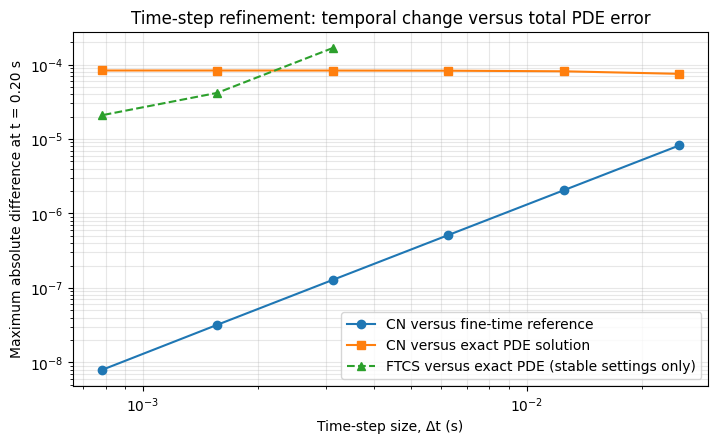

In [ ]:
# @title 💻 Example 2: Time-step refinement — FTCS versus Crank–Nicolson

from scipy.linalg import lu_factor, lu_solve

# ============================================================
# 1. DEFINE THE TWO SOLVERS USING THE SAME GRID AND BOUNDARIES
# ============================================================

def ftcs_history(initial, r, number_of_steps):
    """Store each FTCS temperature profile; endpoints remain zero."""
    current = initial.copy()
    history = [current.copy()]

    for step in range(number_of_steps):
        updated = current.copy()          # A new array holds future values

        for j in range(1, len(current) - 1):
            updated[j] = current[j] + r * (
                current[j-1] - 2*current[j] + current[j+1]
            )

        updated[0], updated[-1] = 0.0, 0.0  # Dirichlet boundaries
        current = updated
        history.append(current.copy())

    return np.asarray(history)


def crank_nicolson_history(initial, r, number_of_steps):
    """Store CN profiles; solve the same tridiagonal system each step."""
    current = initial.copy()
    history = [current.copy()]
    m = len(initial) - 2                 # Unknowns: interior nodes only

    # Construct A and B, as in Example 1, but for any number of nodes.
    A = np.diag((1 + r) * np.ones(m))
    A += np.diag((-r/2) * np.ones(m - 1), 1)
    A += np.diag((-r/2) * np.ones(m - 1), -1)

    B = np.diag((1 - r) * np.ones(m))
    B += np.diag((r/2) * np.ones(m - 1), 1)
    B += np.diag((r/2) * np.ones(m - 1), -1)

    # The matrix A does not change: reuse its LU factorisation.
    factors = lu_factor(A)

    for step in range(number_of_steps):
        rhs = B @ current[1:-1]          # Known temperatures: interior
        updated = current.copy()
        updated[1:-1] = lu_solve(factors, rhs)  # Simultaneous solve
        updated[0], updated[-1] = 0.0, 0.0
        current = updated
        history.append(current.copy())

    return np.asarray(history)


# ============================================================
# 2. COMPARE ERRORS AT THE SAME PHYSICAL TIME AND SPATIAL GRID
# ============================================================

L, D = 1.0, 0.10                     # Same illustrative diffusion model
Nx = 41                              # Fixed number of spatial nodes
final_time = 0.20                    # Every run ends at exactly this time
x = np.linspace(0.0, L, Nx)
dx = x[1] - x[0]
initial = np.sin(np.pi * x / L)       # Zero at both ends
exact = np.exp(-D * (np.pi/L)**2 * final_time) * initial

step_counts = [8, 16, 32, 64, 128, 256]
records = []

# A very fine TIME discretisation on the SAME spatial grid provides
# a numerical reference for how the CN solution changes with dt.
reference_steps = 2048
reference_r = D * (final_time / reference_steps) / dx**2
cn_time_reference = crank_nicolson_history(
    initial, reference_r, reference_steps)[-1]

for Nt in step_counts:
    dt = final_time / Nt
    r = D * dt / dx**2

    # CN is stable for any r for this standard linear diffusion problem.
    cn_final = crank_nicolson_history(initial, r, Nt)[-1]
    cn_total_error = np.max(np.abs(cn_final - exact))
    cn_time_error = np.max(np.abs(cn_final - cn_time_reference))

    # Only report an FTCS result if its overall stability condition holds.
    if r <= 0.5:
        ftcs_final = ftcs_history(initial, r, Nt)[-1]
        ftcs_error = np.max(np.abs(ftcs_final - exact))
    else:
        ftcs_error = np.nan           # Unstable parameter choice

    records.append((Nt, dt, r, cn_time_error, cn_total_error, ftcs_error))
    ftcs_text = f'{ftcs_error:.3e}' if np.isfinite(ftcs_error) else 'not allowed'
    print(f'Nt={Nt:3d} | r={r:5.2f} | CN time-step error={cn_time_error:.3e} | '
          f'CN total error={cn_total_error:.3e} | FTCS total error={ftcs_text}')

# ============================================================
# 3. PLOT ERROR AGAINST TIME-STEP SIZE
# ============================================================

dt_values = np.array([row[1] for row in records])
cn_time_errors = np.array([row[3] for row in records])
cn_total_errors = np.array([row[4] for row in records])
ftcs_total_errors = np.array([row[5] for row in records])

plt.figure(figsize=(8.2, 4.6))
plt.loglog(dt_values, cn_time_errors, 'o-', label='CN versus fine-time reference')
plt.loglog(dt_values, cn_total_errors, 's-', label='CN versus exact PDE solution')
plt.loglog(dt_values, ftcs_total_errors, '^--',
           label='FTCS versus exact PDE (stable settings only)')
plt.xlabel('Time-step size, Δt (s)')
plt.ylabel('Maximum absolute difference at t = 0.20 s')
plt.title('Time-step refinement: temporal change versus total PDE error')
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.show()

**How to read Example 2:**

1. **Check the diffusion number.** FTCS is excluded when $r>0.5$ because that choice does not satisfy its general stability condition. Crank–Nicolson can be run for those values.
2. **Follow the Crank–Nicolson time-step error.** As $\Delta t$ is halved, its difference from the fine-time reference should drop by **approximately a factor of four** (second-order temporal behaviour) over the useful refinement range.
3. **Compare against the exact PDE solution.** This is a different test. Because the spatial grid is fixed, its error does not necessarily decrease monotonically as $\Delta t$ decreases: **spatial and temporal errors can partially cancel**. The total error eventually approaches a *spatial-error floor*.
4. **Compare computational work.** FTCS uses inexpensive node updates. Crank–Nicolson forms and solves a linear system, although here its matrix factorisation is reused. Total run time depends on both **work per step** and **number of steps**.

> **Try it:** Change `Nx = 41` to `Nx = 21` and rerun. Does the total error level change? The fine-time numerical reference only isolates time-step effects **on whichever spatial grid you have chosen**.

## 📂 11.5.6 Stability advantage — and an important limitation

We can compare the **amplification of a single spatial error mode** without repeating the full von Neumann derivation from Notebook 11.1. Let $s=\sin^2(k\Delta x/2)$, where $0\leq s\leq1$.

| Scheme | Amplification factor for the mode | Stability of standard 1D linear diffusion |
|---|---|---|
| FTCS | $G_{\mathrm{FTCS}}=1-4rs$ | All modes stable if $0\leq r\leq1/2$ |
| Crank–Nicolson | $\displaystyle G_{\mathrm{CN}}=\frac{1-2rs}{1+2rs}$ | $|G_{\mathrm{CN}}|\leq1$ for every $r\geq0$ |

The denominator in $G_{\mathrm{CN}}$ is always positive. For diffusion ($r\geq0$), the numerator's absolute value cannot exceed that denominator, so **the amplification magnitude does not exceed one regardless of the time step**. This is called **unconditional linear stability** for the stated model and discretisation.

**However, stability is not the same as smooth, accurate behaviour.** For the highest-frequency mode, $s\approx1$, so

$$G_{\mathrm{CN,high}}\approx\frac{1-2r}{1+2r}.$$

When $r>1/2$, this factor is negative: the mode alternates in sign even though its magnitude does not grow. If $r$ is *very large*, $G_{\mathrm{CN,high}}\approx-1$, so a high-frequency disturbance can **alternate while decaying only slowly per numerical step**. This is unlike the physical diffusion of very short spatial fluctuations, which should damp rapidly.

The practical lesson is:

> **Crank–Nicolson removes the FTCS stability limit for this linear diffusion problem, but does not remove the need for a suitable time step and checks for accuracy or oscillations.**

### 🔹 Interactive exploration — Change space and time discretisation

Keep the **physical rod length**, **diffusivity** and **final simulation time** unchanged. Use the controls to change **$N_x$ (spatial nodes)** and **$N_t$ (time steps)**. The code calculates $\Delta x$, $\Delta t$ and $r$, then runs **both schemes** from the same initial temperature profile.

We add a **small rapidly varying disturbance** to an otherwise smooth temperature field. This is deliberately chosen to reveal the different behaviour of the numerical methods when $r$ is large. The plots show the disturbed temperature field and how the disturbance amplitude changes.

**Predict first:** If you select a finer spatial grid but leave $N_t$ unchanged, what happens to $r$? Will FTCS remain stable? What happens to the Crank–Nicolson disturbance?

In [ ]:
# @title 🔧 Set up interactive widgets (run once)

# ipywidgets supplies the dropdowns and sliders used in the next cell.
# It is usually available in Jupyter and Colab; if not, install it.
import importlib.util

widgets = None
try:
    if importlib.util.find_spec('ipywidgets') is None:
        import subprocess
        import sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ipywidgets'])

    import ipywidgets as widgets
    from IPython.display import display
    print(f'ipywidgets {widgets.__version__} is available.')
except Exception as exc:
    # The plot function in the next cell will still work directly.
    print('Interactive widgets could not be loaded:', exc)
    print('Use the direct function call offered in the next cell.')

ipywidgets 7.7.1 is available.


In [ ]:
# @title 🎛️ Interactive FTCS versus Crank–Nicolson stability explorer

# Run Example 2 first: this cell uses ftcs_history(),
# crank_nicolson_history(), numpy and matplotlib.

def explore_cn(Nx=41, Nt=80):
    """Compare both numerical methods at one common physical final time."""

    # ------------------------------------------------------------
    # 1. CHANGE ONLY DISCRETISATION; KEEP THE PHYSICS FIXED
    # ------------------------------------------------------------
    L, D = 1.0, 0.10
    final_time = 0.20

    x = np.linspace(0.0, L, Nx)
    dx = x[1] - x[0]
    dt = final_time / Nt
    r = D * dt / dx**2
    times = np.linspace(0.0, final_time, Nt + 1)

    # ------------------------------------------------------------
    # 2. PREPARE A SMOOTH FIELD AND A SMALL HIGH-FREQUENCY ERROR
    # ------------------------------------------------------------
    smooth = np.sin(np.pi * x / L)
    disturbance = 0.025 * np.sin((Nx - 2) * np.pi * x / L)
    initial = smooth + disturbance

    # Every simulation uses the SAME initial condition and endpoint values.
    ftcs = ftcs_history(initial, r, Nt)
    cn = crank_nicolson_history(initial, r, Nt)

    # Run the error mode alone to measure its amplification separately.
    ftcs_error = ftcs_history(disturbance, r, Nt)
    cn_error = crank_nicolson_history(disturbance, r, Nt)

    initial_size = np.max(np.abs(disturbance))
    ftcs_growth = np.max(np.abs(ftcs_error), axis=1) / initial_size
    cn_growth = np.max(np.abs(cn_error), axis=1) / initial_size

    # Exact result for the SMOOTH initial part only, not the added error.
    exact_smooth = np.exp(-D * (np.pi/L)**2 * final_time) * smooth

    # Amplification of the particular high-frequency sine disturbance.
    s_high = np.cos(np.pi / (2 * (Nx - 1)))**2
    G_ftcs = 1 - 4*r*s_high
    G_cn = (1 - 2*r*s_high) / (1 + 2*r*s_high)

    # ------------------------------------------------------------
    # 3. EXPLAIN THE CHOSEN SETTINGS IN EVERY RUN
    # ------------------------------------------------------------
    print(f'Nx = {Nx} nodes; Nt = {Nt} steps; final time = {final_time:.2f} s')
    print(f'dx = {dx:.5f} m | dt = {dt:.6f} s | Fourier number r = {r:.3f}')
    print(f'High-frequency amplification per step: FTCS {G_ftcs:+.3f}; '
          f'Crank–Nicolson {G_cn:+.3f}')
    print('FTCS:', 'stability condition satisfied' if r <= 0.5
          else 'STABILITY CONDITION VIOLATED')
    print('Crank–Nicolson: linearly stable for this diffusion problem.')
    print(f'Final disturbance / initial: FTCS {ftcs_growth[-1]:.3e}; '
          f'Crank–Nicolson {cn_growth[-1]:.3e}')

    if G_cn < 0:
        print('CN high-frequency mode alternates in sign: check damping and accuracy.')

    # ------------------------------------------------------------
    # 4. PLOT FINAL FIELDS AND DISTURBANCE AMPLIFICATION
    # ------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))

    axes[0].plot(x, exact_smooth, 'k:', label='Exact smooth solution')
    axes[0].plot(x, cn[-1], '-', label='Crank–Nicolson (disturbed)')
    axes[0].plot(x, ftcs[-1], '--', label='FTCS (disturbed)')
    axes[0].set_xlabel('Position x (m)')
    axes[0].set_ylabel('Temperature (illustrative)')
    axes[0].set_title('Final temperature at the SAME physical time')
    axes[0].set_ylim(-0.35, 1.35)
    axes[0].grid(alpha=0.3)
    axes[0].legend(fontsize=8)

    # If FTCS blows up, keep the useful CN temperature visible.
    if np.max(np.abs(ftcs[-1])) > 1.35:
        axes[0].text(0.5, 0.03, 'FTCS values clipped; see disturbance plot',
                     transform=axes[0].transAxes, ha='center', fontsize=8,
                     color='darkred')

    axes[1].semilogy(times, np.maximum(ftcs_growth, 1e-15), '--',
                     label='FTCS disturbance')
    axes[1].semilogy(times, np.maximum(cn_growth, 1e-15), '-',
                     label='CN disturbance')
    axes[1].axhline(1.0, color='black', linestyle=':', linewidth=1)
    axes[1].set_xlabel('Physical time (s)')
    axes[1].set_ylabel('Disturbance / initial disturbance')
    axes[1].set_title('Growth or decay of a small numerical disturbance')
    axes[1].grid(alpha=0.3, which='both')
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    return {'r': r, 'ftcs_condition_met': r <= 0.5,
            'cn_growth': float(cn_growth[-1]),
            'ftcs_growth': float(ftcs_growth[-1])}


# ------------------------------------------------------------
# 5. ADD CONTROLS; DIRECT FUNCTION CALL REMAINS AVAILABLE
# ------------------------------------------------------------
if widgets is not None:
    grid_choice = widgets.Dropdown(
        options=[('21 nodes', 21), ('41 nodes', 41), ('81 nodes', 81)],
        value=41, description='Space:')

    time_choice = widgets.SelectionSlider(
        options=[10, 20, 40, 80, 160, 320, 640], value=80,
        description='Time steps:', continuous_update=False)

    # The plot is recalculated whenever a control is changed.
    output = widgets.interactive_output(
        explore_cn, {'Nx': grid_choice, 'Nt': time_choice})
    display(widgets.VBox([grid_choice, time_choice, output]))
else:
    print('Widgets unavailable. Call the function directly, for example:')
    print('explore_cn(Nx=81, Nt=80)')
    explore_cn(Nx=41, Nt=80)

# Optional direct use in a new cell: explore_cn(Nx=81, Nt=40)

**Your turn — Predict → Change → Observe → Explain**

1. **Start** with $N_x=41$ and $N_t=80$. Check $r$ and compare both numerical results with the smooth reference curve.
2. **Keep $N_t=80$ and increase $N_x$ to 81.** Predict the new $r$ before viewing the printed result. Which method now violates its stability condition?
3. **Keep $N_x=81$ and increase $N_t$ to 320.** Does the FTCS disturbance decay again? What change in computational cost would you expect?
4. **Choose $N_x=81$, $N_t=10$.** Crank–Nicolson remains stable, but observe the high-frequency amplification factor and disturbance curve. Does a negative factor necessarily mean numerical instability? Does a stable result guarantee that a coarse time step is accurate?

If the widget controls do not display in your environment, use a new Python cell to run, for example:

```python
explore_cn(Nx=81, Nt=80)
```

Change either argument and rerun the cell. If using Google Colab and the widget still fails to render after installation, restart the runtime and run the notebook cells in order; the direct call works independently of widget rendering.

## 📂 11.5.7 Which method should an engineer choose?

| Consideration | FTCS (explicit) | Backward Euler (implicit) | Crank–Nicolson (implicit) |
|---|---|---|---|
| Time accuracy | First order | First order | **Second order** for smooth solutions |
| Space accuracy | Second order | Second order | Second order |
| Stability for 1D linear diffusion | Requires $r\leq1/2$ | Unconditionally linearly stable | Unconditionally linearly stable |
| Work in each time step | Direct node updates | Solve a coupled system | Solve a coupled system |
| At very large steps | May become unstable | Strong damping, but possible large time error | May leave sign-alternating high-frequency errors weakly damped |

For a **fine spatial grid or longer physical simulation**, implicit time marching can be attractive because it avoids the explicit stability restriction. For a **small, short calculation**, FTCS may be simpler and entirely adequate.

A good method choice should consider **the actual accuracy needed**, the physical timescales being resolved, grid/time-step convergence, the reliability of the boundary conditions and the total computational work. Do not select Crank–Nicolson solely because it permits a large time step.

> **Important difference:** Solving $A\mathbf T^{n+1}=\mathbf b$ to a small residual checks the **linear algebra** at one time level. It does not prove that $\Delta x$ or $\Delta t$ is sufficiently fine, nor does it validate the heat-transfer model against experimental data.

# ✅ Key takeaways and practice

- **Backward Euler uses future-time spatial values**, producing a coupled linear system; all three schemes still advance forward in physical time.
- **Crank–Nicolson averages the spatial diffusion terms** at the current and future time levels.
- The next temperatures appear **together** in a tridiagonal linear system: $A\mathbf T^{n+1}=B\mathbf T^n$ (plus boundary terms when applicable).
- For smooth solutions, its discretisation error is $O(\Delta t^2+\Delta x^2)$.
- For the stated constant-coefficient linear diffusion problem, it is **unconditionally linearly stable**, unlike FTCS.
- **Unconditionally stable does not mean unconditionally accurate**: very large time steps may produce poorly damped, sign-alternating high-frequency modes.
- The method's benefit should be evaluated against the **cost of solving a linear system each step** and the accuracy required.

### 🚀 Quick practice

1. **Concept:** Why is backward Euler called *backward* if the simulation still moves forward in time? Which temperatures at $n+1$ are unknown in its update?
2. **Calculation:** For $r=0.4$, write the middle-row equation of the three-interior-node **backward-Euler** system, then compare its coefficients with the Crank–Nicolson equation.
3. **Interpretation:** If an FTCS simulation has $r=1.2$, is it within the standard 1D diffusion stability limit? Would Crank–Nicolson be stable for the same $r$? Must its result be accurate?
4. **Engineering judgment:** Why might a simulation benefit from reusing the LU factorisation of $A$, and what changes to $D$, $\Delta t$ or $\Delta x$ would invalidate that reuse?

Try to **predict → calculate → run → inspect → explain**, and use an analytical, benchmark or refined-grid solution when available.

# 🔗 Week 11 wrap-up — From PDEs to trustworthy numerical solutions

Across Week 11, we have moved from **explicit time marching** (11.1), through **boundary conditions** (11.2) and **elliptic linear systems** (11.3), to **stability and resolution** (11.4), and finally to **implicit time marching** (11.5).

The wider engineering lesson is that a numerical solution must be checked at several levels: **correct PDE and boundary conditions → correct discretisation → appropriate stability and accuracy → adequate algebraic solution → numerical convergence → physical validation where evidence is available**.

# 📚 References and source notes (optional further reading)

- **Chapra, S. C. and Canale, R. P.** *Numerical Methods for Engineers*, 8th ed., **§30.3 (pp. 891–895)**: explicit versus implicit stencils and tridiagonal systems. **§30.4 (pp. 895–897)**: Crank–Nicolson time-centering, matrix form and a worked rod example. **§30.4.1 (p. 897)**: comparison with analytical diffusion solutions and time-step accuracy.
- **LeVeque, R. J.** *Finite Difference Methods for Ordinary and Partial Differential Equations*, SIAM (2007), **Ch. 9 (pp. 181–184)**: FTCS, backward Euler and Crank–Nicolson for diffusion, matrix formulation and truncation error. **§9.3–9.4 (pp. 186–188)**: stability, stiffness and why an implicit method permits larger time steps.

**Notation note:** This notebook consistently uses $r=D\Delta t/(\Delta x)^2$, matching Notebook 11.4 and Chapra's $\lambda$. Some presentations (including LeVeque's Eq. 9.8 with $D=1$) instead define $r=\Delta t/[2(\Delta x)^2]$. The formulas agree after accounting for this factor of two.

The notebook intentionally **does not** cover matrix eigenvalue proofs, general nonlinear diffusion, multidimensional Crank–Nicolson or specialised tridiagonal algorithms. These are appropriate extensions once the core method is understood.

**Figures:** The time–space stencil and time-evaluation diagrams in §11.5.2–11.5.3 were newly prepared for these notes; they are schematics rather than reproductions of textbook figures.

# 🤖 AI Acknowledgment

This teaching notebook was prepared with assistance from OpenAI ChatGPT (GPT-6) for drafting Python examples and grammatical proofreading. Its examples were executed and checked for numerical consistency during drafting. All outputs from the LLM were proofread and edited by the teaching team (YCV) before final release.